# Byte-pair encoding, from scratch

**SE201 — AI-Driven Software Engineering, Week 1**

Build a tokeniser in Python

1. Load a corpus
2. Learn a vocabulary using BPE
3. Use that vocabulary to turn text into token IDs, and back again

**Nothing** here is a neural network. The tokeniser is trained **before** the model
and never changes afterwards. 

## 1. Load a corpus

We use the Python standard library. It is already on your machine, needs no
download, and is *code*.  Feel free to download some other corpus and see what happens.

To use your own corpus, set `CORPUS_PATH` to a file or a folder.

In [1]:
import glob, os, re, sysconfig, time
from collections import Counter

CORPUS_PATH = None        # e.g. "/path/to/your/text" — a file or a folder
MAX_CHARS   = 800000      # keep the notebook quick; raise it if you like
N_MERGES    = 800         # vocabulary = base characters + this many merges

def load_corpus(path=None, max_chars=MAX_CHARS):
    if path is None:
        folder = sysconfig.get_paths()["stdlib"]
        files = sorted(glob.glob(os.path.join(folder, "*.py")))
    elif os.path.isdir(path):
        files = sorted(glob.glob(os.path.join(path, "**", "*.*"), recursive=True))
    else:
        files = [path]
    chunks, total = [], 0
    for f in files:
        try:
            # Note: we are reading this as text encoded with utf-8
            t = open(f, encoding="utf-8", errors="ignore").read()
        except (OSError, UnicodeError):
            continue
        chunks.append(t)
        total += len(t)
        if total >= max_chars:
            break
    return "\n".join(chunks)[:max_chars]

text = load_corpus(CORPUS_PATH)
print(f"corpus: {len(text):,} characters, "
      f"{len(text.encode('utf-8')):,} bytes, "
      f"{len(set(text)):,} distinct characters")
print("\n--- first 300 characters " + "-" * 40)
print(text[:300])

corpus: 800,000 characters, 800,000 bytes, 96 distinct characters

--- first 300 characters ----------------------------------------
"""Record of phased-in incompatible language changes.

Each line is of the form:

    FeatureName = "_Feature(" OptionalRelease "," MandatoryRelease ","
                              CompilerFlag ")"

where, normally, OptionalRelease < MandatoryRelease, and both are 5-tuples
of the same form as sys.


## 2. Pre-tokenisation

BPE almost never merges across word boundaries. (There are are rare variants that do.  Don't worry about them!)

Before counting anything we split the text into small pieces — roughly words, numbers, punctuation runs and
whitespace runs — and BPE then works *inside* each piece.

The regex below is close to the one used by GPT-2. See figure 2.15 of Jurafsky and Martin.

The biggest difference is that we are using UTF-8, which has 256 values - basically ASCII text.  Each character is represented by exactly one byte.

Real BPE uses variable length unicode, which encodes almost any symbol in any language with between 1 and 4 bytes.  The algorithm can therefore work with Mandarin, Farsi, etc, without modification

In the merge step, it actually compares neighboring *bytes*, not neighboring *characters*.  However, we will assume that each character _is_ one byte for the sake of simplicity!

Note:
* **A leading space belongs to the word.** `" the"` and `"the"` are different
  tokens, which is why token counts change when you reformat text.

* **Whitespace is swapped for visible stand-ins** — `Ġ` for a space, `Ċ` for a
  newline, `Ĉ` for a tab — so boundaries can be read, and so the mapping is
  exactly reversible.  GPT-2 also uses these unicode characters when it runs BPE.

In [2]:
# regex
# split the text into separate words
PAT = re.compile(r"""
    '(?:s|t|re|ve|m|ll|d)   # common English contractions
  | [ ]?[A-Za-z]+           # a word, with its leading space
  | [ ]?\d+                 # a number
  | [ ]?[^\sA-Za-z\d]+      # punctuation and symbols
  | \s+(?!\S)               # trailing whitespace
  | \s+                     # any other whitespace run
""", re.VERBOSE)

SPACE, NEWLINE, TAB = "Ġ", "Ċ", "Ĉ"      # Ġ  Ċ  Ĉ
# especially important for corpus that contain python code --> to account for indentation

def replace_whitespace(s):
    return s.replace(" ", SPACE).replace("\n", NEWLINE).replace("\t", TAB)

def revert_whitespace(s):
    return s.replace(SPACE, " ").replace(NEWLINE, "\n").replace(TAB, "\t")

assert not (set(text) & {SPACE, NEWLINE, TAB}), "corpus already uses our stand-ins"

def pretokenise(t):
    return PAT.findall(t)

pieces = pretokenise(text)
word_freq = Counter(pieces)

print(f"{len(pieces):,} pre-tokens, {len(word_freq):,} distinct\n")
print(f"{'pre-token':<18}{'count':>10}")
print("-" * 28)
for w, c in word_freq.most_common(100):
    print(f"{replace_whitespace(w):<18}{c:>10,}")

193,039 pre-tokens, 8,582 distinct

pre-token              count
----------------------------
_                      9,591
.                      5,880
ĊĠĠĠĠĠĠĠ               5,572
,                      5,541
(                      4,441
Ġ'                     3,867
Ċ                      3,351
/                      3,088
Ġ=                     3,027
ĊĠĠĠĠĠĠĠĠĠĠĠ           3,020
Ġself                  2,853
)                      2,654
:                      2,540
':                     2,080
Ġif                    2,040
ĊĠĠĠ                   1,956
._                     1,953
Ġthe                   1,841
Ġ#                     1,792
):                     1,463
self                   1,456
Ġreturn                1,385
ĊĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠ       1,369
ĊĊĠĠĠ                  1,348
1                      1,252
Ġis                    1,224
Ġ1                     1,141
Ġ_                     1,112
',                     1,102
-                        995
Ġdef                     990
0      

## 3. Train the merges

The whole algorithm:

* Start with every pre-token split into single characters
* Count every adjacent pair across the corpus, weighted by how often the
  pre-token occurs. Do this within words only.
* Merge the most frequent pair everywhere, and record it
* Repeat until the vocabulary is the size you asked for

Ties break deterministically, so two runs on the same corpus produce the same
tokeniser.

In [3]:
def train_bpe(word_freq, n_merges, log_every=200):
    """Classic BPE. Returns the ordered merge list.

    word_freq maps each distinct pre-token to the number of times it occurred.
    Training on distinct pre-tokens rather than on the raw text is the one
    real optimisation here: " the" turns up tens of thousands of times but is
    only rewritten once per merge, with its count carried along as a weight.
    """
    # Step 1: every pre-token starts as a tuple of single characters, exactly
    # as on the worksheet. Tuples rather than lists because they are hashable,
    # so they can be dictionary keys.
    vocab = {tuple(replace_whitespace(w)): c for w, c in word_freq.items()}
    merges, t0 = [], time.time()

    for step in range(n_merges):
        # -- Step 2: count every adjacent pair ---------------------------
        # zip(syms, syms[1:]) is the sliding window of neighbours:
        # ('c','a','t') yields ('c','a') then ('a','t'). Each pair is credited
        # with c, the number of times this pre-token occurs in the corpus, so
        # a pair inside a common word outranks the same pair inside a rare one.
        #
        # We recount everything from scratch on every merge. That is O(corpus)
        # per merge and is why this notebook stops at a few hundred. Real
        # trainers keep the counts incrementally and only revisit the words a
        # merge actually touched.
        pairs = Counter()
        for syms, c in vocab.items():
            for a, b in zip(syms, syms[1:]):
                pairs[(a, b)] += c
        if not pairs:
            break                     # every pre-token is now a single token

        # -- Step 3: pick the winner --------------------------------------
        # max on the tuple (count, pair) sorts by count first and uses the pair
        # itself to break ties, so the result never depends on dictionary ordering.
        # Deterministic, but arbitrary: this is *our* tie-break rule,
        # and a different implementation would produce a different merge list
        # from the same corpus. Merge lists are not portable between tools.
        (A, B), count = max(pairs.items(), key=lambda kv: (kv[1], kv[0]))

        # The ORDER of this list is the tokeniser, every bit as much as the
        # pieces are. Encoding later replays it from the top.
        merges.append(((A, B), count))

        # -- Step 4: apply that merge everywhere ---------------------------
        # Rewrite every pre-token, replacing an A immediately followed by a B
        # with the single new symbol AB. Left to right and non-overlapping:
        # in ('a','a','a') the merge a+a fires once and gives ('aa','a'),
        # because j jumps forward by two when it matches.
        AB = A + B   # The two tokens to merge
        new = {}     # The updated dictionary
        for syms, c in vocab.items():
            if len(syms) == 1:
                new[syms] = c         # a one-symbol word: nothing left to do
                continue
            out, j = [], 0
            while j < len(syms):
                if j < len(syms) - 1 and syms[j] == A and syms[j + 1] == B:
                    # a case of A followed by B
                    out.append(AB); j += 2      # consume both symbols
                else:
                    #NOT a case of A followed by B
                    out.append(syms[j]); j += 1  
            new[tuple(out)] = c
        vocab = new                   # ... and round again, on the merged text

        if log_every and (step + 1) % log_every == 0:
            print(f"  {step + 1:>4} merges  ({time.time() - t0:5.1f}s)")
    #NOTE - we return the list of merges, not the vocab.  For BPE, the merges are the imporant part
    #NOT the raw vocabulary
    return merges

In [4]:
merges = train_bpe(word_freq, N_MERGES)
print(f"\nlearned {len(merges)} merges\n")

print(f"{'#':>4}  {'pair':<24}{'count':>10}   {'new token'}")
print("-" * 60)
for i, ((a, b), c) in enumerate(merges[:100], 1):
    print(f"{i:>4}  {a + '  +  ' + b:<24}{c:>10,}   {a + b}")

   200 merges  (  2.2s)
   400 merges  (  4.0s)
   600 merges  (  5.7s)
   800 merges  (  7.4s)

learned 800 merges

   #  pair                         count   new token
------------------------------------------------------------
   1  Ġ  +  Ġ                    132,228   ĠĠ
   2  ĠĠ  +  ĠĠ                   50,145   ĠĠĠĠ
   3  ĠĠ  +  Ġ                    15,310   ĠĠĠ
   4  Ċ  +  ĠĠĠĠ                  12,787   ĊĠĠĠĠ
   5  s  +  e                      8,245   se
   6  i  +  n                      6,770   in
   7  o  +  n                      6,611   on
   8  ĊĠĠĠĠ  +  ĠĠĠ                6,412   ĊĠĠĠĠĠĠĠ
   9  ĊĠĠĠĠ  +  ĠĠĠĠ               6,317   ĊĠĠĠĠĠĠĠĠ
  10  r  +  e                      5,918   re
  11  Ġ  +  '                      5,565   Ġ'
  12  e  +  r                      5,304   er
  13  t  +  h                      5,114   th
  14  Ġ  +  a                      4,614   Ġa
  15  d  +  e                      4,575   de
  16  se  +  l                     4,360   sel
  17  t  +  e

For Python source the earliest merges are **runs of spaces**.  The tokeniser spends its first slots discovering indentation. For English prose it would learn `th`, `in`, `re` instead.

## 4. The vocabulary

Every base character, plus every merge, in the order learned. Each entry gets
an integer ID — and that ID is the only thing the model ever sees.

In [5]:
base = sorted({ch for w in word_freq for ch in replace_whitespace(w)})
tokens = base + [a + b for (a, b), _ in merges]

id_of = {t: i for i, t in enumerate(tokens)}
token_of = {i: t for t, i in id_of.items()}
rank = {pair: i for i, (pair, _) in enumerate(merges)}     # merge order

print(f"vocabulary: {len(tokens):,} tokens "
      f"({len(base)} base characters + {len(merges)} merges)\n")

print("the first 20 IDs — base characters")
print("  " + "  ".join(f"{i}:{token_of[i]!r}" for i in range(20)))

print("\na few merged tokens, with their IDs")
for i in [len(base) + k for k in (0, 5, 20, 60, 150, 300, 500, len(merges) - 1)]:
    print(f"  {i:>5}  {token_of[i]!r}")

vocabulary: 896 tokens (96 base characters + 800 merges)

the first 20 IDs — base characters
  0:'!'  1:'"'  2:'#'  3:'$'  4:'%'  5:'&'  6:"'"  7:'('  8:')'  9:'*'  10:'+'  11:','  12:'-'  13:'.'  14:'/'  15:'0'  16:'1'  17:'2'  18:'3'  19:'4'

a few merged tokens, with their IDs
     96  'ĠĠ'
    101  'in'
    116  'or'
    156  'Ġ_'
    246  'string'
    396  'ĠF'
    596  'pend'
    895  'mplemented'


### The dictionary in both directions

This is all a tokeniser really is: a string ↔ integer map, plus the rule for
splitting a word into entries of that map.

In [6]:
def segment_word(piece):
    """Apply the learned merges to one pre-token, in the order they were learned.

    Encoding is not a dictionary lookup of the whole word. It is a replay of
    training on a single word: the same merges, in the same order. That is why
    the merge list has to ship alongside the vocabulary, and why its order is
    part of the tokeniser rather than an implementation detail.
    """
    syms = list(replace_whitespace(piece))        # Step 1 again: single characters
    while len(syms) > 1:
        # Find the adjacent pair that was learned EARLIEST -- lowest rank, not
        # the most frequent one in this word. Merge 3 has to fire before merge
        # 40 even when both match, otherwise we would not reproduce what
        # training produced, and the IDs would not mean what the model expects.
        best, at = None, None
        for j, pair in enumerate(zip(syms, syms[1:])):
            r = rank.get(pair)        # None => this pair was never merged
            if r is not None and (best is None or r < best):
                best, at = r, j
        if best is None:
            break                     # no learned pair left: the word is done

        # Apply only that one merge, then start looking again, because joining
        # two symbols creates a new neighbour that may itself be a learned
        # pair -- this is how "lo" + "w" only becomes reachable once l + o has
        # fired. Training could apply a merge everywhere at once; here the
        # word is short, so one at a time is clearer and costs nothing.
        syms[at:at + 2] = [syms[at] + syms[at + 1]]
    return syms

print(f"{'word':<18}{'pieces':<34}{'ids'}")
print("-" * 78)
for w in [" the", " def", " return", " tokeniser", " engineering",
          " unforgettable", " requirements", " 42", "!!!"]:
    parts = segment_word(w)
    print(f"{replace_whitespace(w):<18}{' | '.join(parts):<34}"
          f"{[id_of.get(p, -1) for p in parts]}")

word              pieces                            ids
------------------------------------------------------------------------------
Ġthe              Ġthe                              [139]
Ġdef              Ġdef                              [177]
Ġreturn           Ġreturn                           [160]
Ġtokeniser        Ġto | ke | n | ise | r            [214, 275, 77, 233, 81]
Ġengineering      Ġen | g | ine | er | ing          [622, 70, 266, 107, 138]
Ġunforgettable    Ġun | for | get | t | able        [638, 478, 290, 83, 366]
Ġrequirements     Ġre | qui | re | ment | s         [128, 707, 105, 263, 82]
Ġ42               Ġ | 4 | 2                         [95, 19, 17]
!!!               ! | ! | !                         [0, 0, 0]


## 5. Tokenise and detokenise

`encode` pre-tokenises, segments each piece, and looks up the IDs.
`decode` looks the IDs back up and undoes the stand-ins.

Note the asymmetry: encoding needs the merge **order**, decoding needs only the
table. That is why decoding is trivial and encoding is not.

In [7]:
UNK = -1

def encode(t):
    out = []
    for piece in pretokenise(t):
        for sym in segment_word(piece):
            out.append(id_of.get(sym, UNK))
    return out

def decode(ids):
    return revert_whitespace("".join(token_of.get(i, "�") for i in ids))

sample = "def encode(text):\n    return [id_of[s] for s in segment(text)]\n"
ids = encode(sample)

print("text    :", repr(sample))
print("ids     :", ids[:24], "..." if len(ids) > 24 else "")
print("tokens  :", " | ".join(token_of[i] for i in ids[:24]))
print("decoded :", repr(decode(ids)))
print("\nround trip exact:", decode(ids) == sample)
print(f"{len(sample)} characters -> {len(ids)} tokens "
      f"({len(sample) / len(ids):.2f} characters per token)")

text    : 'def encode(text):\n    return [id_of[s] for s in segment(text)]\n'
ids     : [439, 622, 762, 7, 173, 146, 118, 160, 549, 349, 62, 78, 69, 58, 82, 60, 211, 179, 149, 511, 70, 263, 7, 173] ...
tokens  : def | Ġen | code | ( | text | ): | ĊĠĠĠ | Ġreturn | Ġ[ | id | _ | o | f | [ | s | ] | Ġfor | Ġs | Ġin | Ġse | g | ment | ( | text
decoded : 'def encode(text):\n    return [id_of[s] for s in segment(text)]\n'

round trip exact: True
63 characters -> 27 tokens (2.33 characters per token)


In [ ]:
# Any text at all — including words the corpus never contained.
for probe in ["unforgettable", "SE201 tokenisation!", "    # a comment",
              "naïve café"]:
    got = encode(probe)
    print(f"{probe!r}")
    print(f"   {len(got):>2} tokens: " + " | ".join(token_of.get(i, "<UNK>")
                                                   for i in got))
    print(f"   round trip: {decode(got) == probe}")

    # ï and é are not in the corpus, so they are <UNK> --> but this won't happen IRL because we start off with a dictionary with all possible characters, so the only way to get <UNK> is to feed in a character that is not in the dictionary (e.g. a Chinese character if the dictionary only contains Latin characters).

'unforgettable'
    5 tokens: un | for | get | t | able
   round trip: True
'SE201 tokenisation!'
   10 tokens: SE | 2 | 0 | 1 | Ġto | ke | n | is | ation | !
   round trip: True
'    # a comment'
    6 tokens: ĠĠĠ | Ġ# | Ġa | Ġco | m | ment
   round trip: True
'naïve café'
    8 tokens: n | a | <UNK> | ve | Ġc | a | f | <UNK>
   round trip: False


The vocabulary is built from
*characters seen in the corpus*, so an accented letter that never appeared is
unknown, and the decode fails!

Production tokenisers avoid this by starting from **bytes** rather than
characters. That single is what "byte-level BPE" means.

## 6. What the vocabulary can tell us

A vocabulary is a compressed description of the corpus it was trained on. Six
things worth measuring.

In [9]:
slice_text = text[:200_000]
corpus_ids = encode(slice_text)
tok_freq = Counter(token_of[i] for i in corpus_ids if i in token_of)

# 1 — compression
cpt = len(slice_text) / len(corpus_ids)
print("1. COMPRESSION")
print(f"   {cpt:.2f} characters per token, "
      f"{len(slice_text.encode()) / len(corpus_ids):.2f} bytes per token")
print("   a production 128k tokeniser reaches roughly 3.5-4.0\n")

# 2 — token length
lengths = [len(t) for t in tokens]
print("2. TOKEN LENGTH")
print(f"   mean {sum(lengths) / len(lengths):.2f} characters, "
      f"longest {max(lengths)} -> {max(tokens, key=len)!r}")
print(f"   single characters still in the vocabulary: "
      f"{sum(1 for L in lengths if L == 1)}\n")

# 3 — tokens per word
words = [w for w in pretokenise(slice_text) if w.strip().isalpha()]
fert = [len(segment_word(w)) for w in words]
print("3. TOKENS PER WORD")
print(f"   mean {sum(fert) / len(fert):.2f}")
print(f"   {sum(1 for f in fert if f == 1) / len(fert):.1%} of words survive "
      f"as a single token\n")

# 4 — where the vocabulary went
ws = sum(1 for t in tokens if set(t) <= {SPACE, NEWLINE, TAB})
alpha = sum(1 for t in tokens if t.replace(SPACE, "").isalpha())
print("4. WHAT THE SLOTS WENT ON")
print(f"   whitespace and indentation : {ws:>5}  ({ws / len(tokens):5.1%})")
print(f"   letters only               : {alpha:>5}  ({alpha / len(tokens):5.1%})")
print(f"   everything else            : {len(tokens) - ws - alpha:>5}\n")

# 5 — coverage
ranked = [c for _, c in tok_freq.most_common()]
total, cum, cover = sum(ranked), 0, []
for c in ranked:
    cum += c
    cover.append(cum / total)
print("5. COVERAGE")
for p in (0.5, 0.8, 0.9, 0.99):
    k = next(i for i, v in enumerate(cover, 1) if v >= p)
    print(f"   {p:>4.0%} of all token occurrences come from the top {k:,} tokens")
print()

# 6 — diminishing returns, measured on held-out text
held = text[200_000:260_000]
def chars_per_token_with(n):
    r = {p: i for i, (p, _) in enumerate(merges[:n])}
    count = 0
    for piece in pretokenise(held):
        syms = list(replace_whitespace(piece))
        while len(syms) > 1:
            best, at = None, None
            for j, pair in enumerate(zip(syms, syms[1:])):
                v = r.get(pair)
                if v is not None and (best is None or v < best):
                    best, at = v, j
            if best is None:
                break
            syms[at:at + 2] = [syms[at] + syms[at + 1]]
        count += len(syms)
    return len(held) / count

sizes = [n for n in (0, 50, 100, 200, 400, 800) if n <= len(merges)]
curve = [chars_per_token_with(n) for n in sizes]
print("6. DIMINISHING RETURNS  (held-out text)")
for n, v in zip(sizes, curve):
    print(f"   {n:>4} merges -> {v:.2f} characters per token")

1. COMPRESSION
   2.84 characters per token, 2.84 bytes per token
   a production 128k tokeniser reaches roughly 3.5-4.0

2. TOKEN LENGTH
   mean 3.52 characters, longest 33 -> 'ĊĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠĠ'
   single characters still in the vocabulary: 96

3. TOKENS PER WORD
   mean 1.99
   55.8% of words survive as a single token

4. WHAT THE SLOTS WENT ON
   whitespace and indentation :    26  ( 2.9%)
   letters only               :   752  (83.9%)
   everything else            :   118

5. COVERAGE
    50% of all token occurrences come from the top 74 tokens
    80% of all token occurrences come from the top 262 tokens
    90% of all token occurrences come from the top 400 tokens
    99% of all token occurrences come from the top 674 tokens

6. DIMINISHING RETURNS  (held-out text)
      0 merges -> 1.00 characters per token
     50 merges -> 1.64 characters per token
    100 merges -> 2.00 characters per token
    200 merges -> 2.42 characters per token
    400 merges -> 2.80 ch

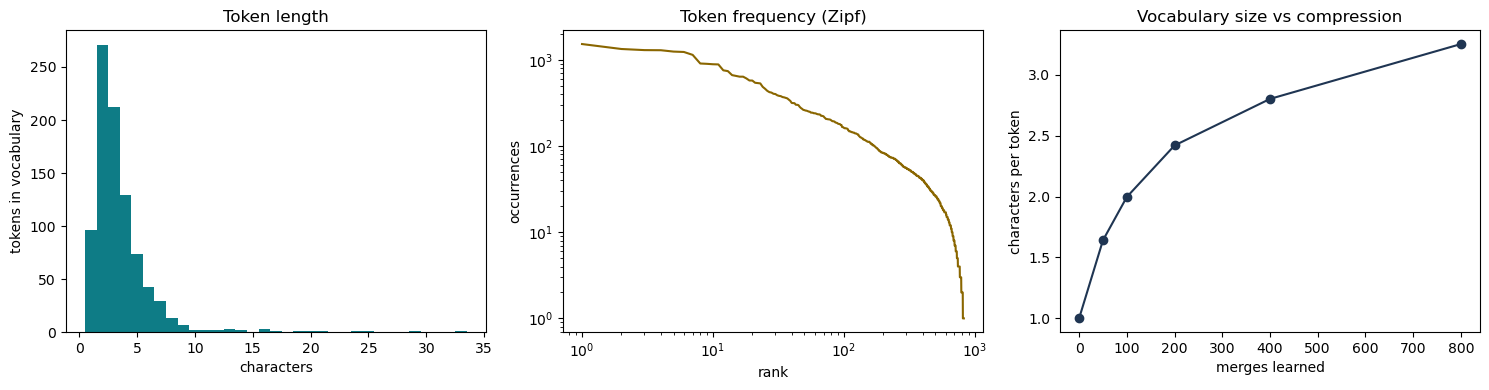

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].hist(lengths, bins=range(1, max(lengths) + 2), align="left", color="#0E7C86")
ax[0].set_title("Token length")
ax[0].set_xlabel("characters"); ax[0].set_ylabel("tokens in vocabulary")

top = tok_freq.most_common()
ax[1].loglog(range(1, len(top) + 1), [c for _, c in top], color="#8A6600")
ax[1].set_title("Token frequency (Zipf)")
ax[1].set_xlabel("rank"); ax[1].set_ylabel("occurrences")

ax[2].plot(sizes, curve, marker="o", color="#1F3552")
ax[2].set_title("Vocabulary size vs compression")
ax[2].set_xlabel("merges learned"); ax[2].set_ylabel("characters per token")
#balance between compression & how the data is displayed on LLM's side (even though we want the dictionary to have all possible combinations to minimise token usage, the compression plateaus, so we just want to balance)

plt.tight_layout(); plt.show()

### What to notice

**Compression** More merges means fewer tokens for the same
text, which makes inference cheaper and allows for more content inside the context window. 

But the third plot bends: each batch of merges gets less additional compression than the last. 
Vocabularies settled at 32k–256k instead of growing without limit.

**Zipf's law** Just a few tokens account for most of the text. 

Zipf's law is an empirical statistical rule stating that in a ranked list of data, the frequency of any item is inversely proportional to its numerical rank.

**The vocabulary is matched to the corpus.** Ours spent a large share of
its slots on whitespace, because it was trained on Python. Train on prose and
those slots go to `th`, `ing`, `tion` instead. 

**Tokens per word** tells you what a tokeniser will cost on *your* text. It is also where other languages
get penalised. The same sentence in a language unrepresented in the
training corpus can cost several times more tokens than in English.

### Exercises
Some exercises you may want to try:

1. Point `CORPUS_PATH` at a folder of plain English text and re-run. Compare the
   first twenty merges. What is share of whitespace in the english vocabulary compared to Python?

2. Train on prose, then measure fertility on code — and the other way round.
   What does the mismatch cost?

3. Raise `N_MERGES` to 2000. Where does the compression curve flatten for English?


## 7. The same task, with a production tokeniser
`tiktoken` is OpenAI's implementation: the same algorithm with the vocabularies that GPT-4 and its successors use.

In [11]:
!pip3 install tiktoken  
try:
    import tiktoken
except ImportError:
    tiktoken = None
    print("tiktoken is not installed.  Run:  pip install tiktoken\n")

WANTED = ("cl100k_base",    # GPT-4, GPT-3.5-turbo, the text-embedding-3 models
          "o200k_base")     # the GPT-4o generation

encs = {}
if tiktoken is not None:
    for name in WANTED:
        try:
            encs[name] = tiktoken.get_encoding(name)
        except Exception as e:
            # Almost always the download: no network, a proxy, or a firewall.
            print(f"could not load {name}  ({type(e).__name__})")

if encs:
    print(f"{'tokeniser':<14}{'vocabulary':>12}")
    print("-" * 26)
    print(f"{'ours':<14}{len(tokens):>12,}")
    for name, e in encs.items():
        print(f"{name:<14}{e.n_vocab:>12,}")
else:
    print("\nNo production tokeniser available, so the cells below will skip.")
    print("They need one download of a few megabytes from")
    print("openaipublic.blob.core.windows.net -- try again on a network that")
    print("allows it, and the result is cached afterwards.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 5.4 MB/s  0:00:00 eta 0:00:01

[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
tokeniser       vocabulary
--------------------------
ours                   896
cl100k_base        100,277
o200k_base         200,019


### Tokenise and detokenise, exactly as before

Same two functions, same sample. A token is a
**byte string**, not a str. A single token is not guaranteed to be valid UTF-8. A three-byte
character can be split across two tokens, and each half is a legitimate token
that means nothing by itself. Therefore, pieces_of replaces invalid UTF-8 fragments as unknowns.

In [ ]:
sample = "def encode(text):\n    return [id_of[s] for s in segment(text)]\n"

def pieces_of(enc, s):
    """Token strings for display. Bytes in, replacement chars for any split."""
    return [enc.decode_single_token_bytes(i).decode("utf-8", "replace")
            for i in enc.encode_ordinary(s)]

def report(name, ids, pieces, s, roundtrip):
    print(f"{name}")
    print(f"   {len(ids):>3} tokens for {len(s)} characters "
          f"({len(s) / len(ids):.2f} chars/token)")
    print("   " + " | ".join(p.replace("\n", "\\n") for p in pieces[:14])
          + (" | ..." if len(pieces) > 14 else ""))
    print(f"   ids: {ids[:14]}{' ...' if len(ids) > 14 else ''}")
    print(f"   round trip exact: {roundtrip}\n")

ours_ids = encode(sample)
report("ours", ours_ids, [token_of.get(i, "?") for i in ours_ids],
       sample, decode(ours_ids) == sample)

for name, enc in encs.items():
    ids = enc.encode_ordinary(sample)
    report(name, ids, pieces_of(enc, sample), sample, enc.decode(ids) == sample)

    #tiktoken does a much better job of compressing (more characters per token/ less tokens per character) than our BPE from scratch, because it has a much larger vocabulary and more merges. 

ours
    27 tokens for 63 characters (2.33 chars/token)
   def | Ġen | code | ( | text | ): | ĊĠĠĠ | Ġreturn | Ġ[ | id | _ | o | f | [ | ...
   ids: [439, 622, 762, 7, 173, 146, 118, 160, 549, 349, 62, 78, 69, 58] ...
   round trip exact: True

cl100k_base
    17 tokens for 63 characters (3.71 chars/token)
   def |  encode | (text | ):\n |     |  return |  [ | id | _of | [s | ] |  for |  s |  in | ...
   ids: [755, 16559, 7383, 997, 262, 471, 510, 307, 3659, 12144, 60, 369, 274, 304] ...
   round trip exact: True

o200k_base
    17 tokens for 63 characters (3.71 chars/token)
   def |  encode | (text | ):\n |     |  return |  [ | id | _of | [s | ] |  for |  s |  in | ...
   ids: [1314, 31288, 13414, 1883, 271, 622, 723, 315, 8023, 24177, 60, 395, 265, 306] ...
   round trip exact: True



### The same six statistics

Measured on the same slice of the same corpus, so the numbers are directly
comparable with section 6.

In [13]:
def vocab_shape(enc):
    """Mean token length, and what the slots were spent on."""
    lens, ws, alpha = [], 0, 0
    for i in range(enc.n_vocab):
        try:
            b = enc.decode_single_token_bytes(i)
        except KeyError:
            continue                       # a special token, e.g. endoftext
        t = b.decode("utf-8", "ignore")
        lens.append(len(b))
        if t and not t.strip():
            ws += 1
        elif t.replace(" ", "").isalpha():
            alpha += 1
    return lens, ws, alpha

# Section 6 already measured all of this for our tokeniser, on this same
# slice. Reuse it rather than spending another minute of pure Python.
#
# The words keep their leading spaces: " the" and "the" are different tokens,
# and stripping the space would misreport every tokeniser here.
fert_words, ours_ids, ours_fert = words, corpus_ids, fert

rows = []
ours_lens = [len(t) for t in tokens]
ours_ws = sum(1 for t in tokens if set(t) <= {SPACE, NEWLINE, TAB})
rows.append(("ours", len(tokens), len(slice_text) / len(ours_ids),
             sum(ours_lens) / len(ours_lens),
             ours_ws / len(tokens),
             sum(ours_fert) / len(ours_fert),
             sum(1 for f in ours_fert if f == 1) / len(ours_fert)))

for name, enc in encs.items():
    # encode_ordinary, not encode: the plain `encode` raises if the text
    # happens to contain a special-token string like "<|endoftext|>". On
    # user-supplied input that is a crash waiting to happen.
    ids = enc.encode_ordinary(slice_text)
    lens, ws, _ = vocab_shape(enc)
    fert = [len(enc.encode_ordinary(w)) for w in fert_words]
    rows.append((name, enc.n_vocab, len(slice_text) / len(ids),
                 sum(lens) / len(lens), ws / enc.n_vocab,
                 sum(fert) / len(fert),
                 sum(1 for f in fert if f == 1) / len(fert)))

hdr = ("tokeniser", "vocab", "chars/tok", "mean len", "whitespace",
       "tokens-per-word", "1-token words")
print(f"{hdr[0]:<14}{hdr[1]:>9}{hdr[2]:>11}{hdr[3]:>10}"
      f"{hdr[4]:>12}{hdr[5]:>11}{hdr[6]:>15}")
print("-" * 82)
for r in rows:
    print(f"{r[0]:<14}{r[1]:>9,}{r[2]:>11.2f}{r[3]:>10.2f}"
          f"{r[4]:>11.1%}{r[5]:>11.2f}{r[6]:>15.1%}")

tokeniser         vocab  chars/tok  mean len  whitespacetokens-per-word  1-token words
----------------------------------------------------------------------------------
ours                896       2.84      3.52       2.9%       1.99          55.8%
cl100k_base     100,277       4.27      6.42       0.6%       1.12          89.4%
o200k_base      200,019       4.23      6.99       0.4%       1.14          87.7%


### What the same text costs under each vocabulary

This is the table that matters commercially. Identical strings, three
tokenisers, and the token count is what you are billed for.

In [14]:
PROBES = [
    ("English prose",   "The quick brown fox jumps over the lazy dog."),
    ("Python code",     "def encode(text):\n    return [id_of[s] for s in xs]\n"),
    ("Deep indent",     "    " * 4 + "return None\n"),
    ("Rare word",       "antidisestablishmentarianism"),
    ("German compound", "Donaudampfschifffahrtsgesellschaft"),
    ("Chinese",         "分词器把文本切成词元"),
    ("Emoji",           "tokenisation \U0001f642\U0001f642"),
]

names = ["ours"] + list(encs)
print(f"{'text':<18}{'chars':>7}" + "".join(f"{n:>14}" for n in names))
print("-" * (25 + 14 * len(names)))
for label, s in PROBES:
    ids = encode(s)
    cells = [f"{len(ids)}{'' if decode(ids) == s else ' !'}"]
    for enc in encs.values():
        cells.append(str(len(enc.encode_ordinary(s))))
    print(f"{label:<18}{len(s):>7}" + "".join(f"{c:>14}" for c in cells))

print("\n!  marks a failed round trip: our vocabulary was built from the")
print("   characters in one Python corpus, so anything outside it is lost.")
print("   The byte-level tokenisers cannot fail this way -- worst case they")
print("   spend more tokens, which is a bill rather than a bug.")

text                chars          ours   cl100k_base    o200k_base
-------------------------------------------------------------------
English prose          44            25            10            10
Python code            52            23            16            16
Deep indent            28             6             4             4
Rare word              28            14             6             6
German compound        34            24            13            10
Chinese                10          10 !            14             9
Emoji                  15           8 !             5             4

!  marks a failed round trip: our vocabulary was built from the
   characters in one Python corpus, so anything outside it is lost.
   The byte-level tokenisers cannot fail this way -- worst case they
   spend more tokens, which is a bill rather than a bug.


### What to notice

**Most of the gap is scale, not cleverness.** Ours reaches roughly 2.3
characters per token; the production vocabularies reach 3.5–4. Same algorithm,
same greedy merges — they have simply been given a hundred times the
vocabulary and many orders of magnitude more text. There is no secret step.

**The two OpenAI vocabularies disagree with each other.** o200k_base has twice
the slots of cl100k_base, so it spends fewer tokens on the same string,
especially for code and for languages other than English. This is the concrete
version of *the tokeniser is welded to the model*: the same prompt has a
different price depending on which model you send it to, and the difference is
not a rounding error.

**Non-English text is where the cost shows up.** Look at the Chinese and German
rows against the English one. A vocabulary trained mostly on English spends its
merges on English, so everything else is spelled out in smaller pieces. Users
in those languages pay more per sentence, fit less in the context window, and
get slower responses — for the same content. It is worth knowing this is a
consequence of a frequency count over a training corpus, not a design choice
anyone made deliberately.

**Deep indentation is the code-specific version of the same effect.** Compare
what our Python-trained tokeniser does to the indent row against what a
general-purpose vocabulary does.

**And the failure mode differs in kind.** Ours can lose characters it never
saw. A byte-level tokeniser cannot — the worst it can do is charge you more.
That is the entire argument for starting from bytes, in one row of a table.